In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import gamma
import ipywidgets as widgets

Question 2

We often study sample averages: It's one of the first statistics you calculate for any dataset. What is the distribution of the sample mean?

Draw n = 32 values from Uniform[-sqrt(3), sqrt(3)]; these are your data. The choice of 
±
3
± 
3
​
  ensures each draw has mean 0 and variance 1.

For this sample, compute the mean and multiply by np.sqrt(n).

Repeat the above process b = 5_000 times and plot the ECDF.

What distribution does this approach as 
n
n increases?

In [3]:
rng = np.random.default_rng(20260717)

In [4]:
n = 32   #one sample

data = np.random.uniform(-np.sqrt(3), np.sqrt(3), n)

mean = np.mean(data)
mean2 = mean * np.sqrt(n)

mean2

np.float64(0.4915095718287636)

In [ ]:
results = []

for i in range(5000): #repeat 5000 times creating the 32 new variables, fidning their mean, and multiplying by sqrt(32).
    data = np.random.uniform(-np.sqrt(3), np.sqrt(3), n)
    mean = np.mean(data)
    mean2 = mean * np.sqrt(n)
    results.append(mean2)

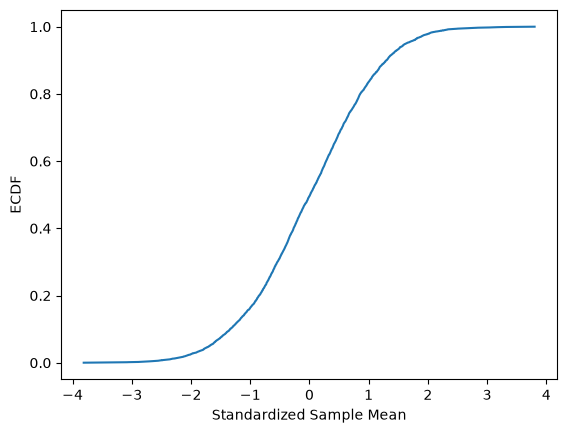

In [7]:
from statsmodels.distributions.empirical_distribution import ECDF
import matplotlib.pyplot as plt

ecdf = ECDF(results)

plt.plot(ecdf.x, ecdf.y)
plt.xlabel("Standardized Sample Mean")
plt.ylabel("ECDF")
plt.show()

This is a normal distribution because the n apporaches 1 from 0 as n increases

Question 5

We're going to draw a sample of values, sort them, and track a particular rank. This is particularly useful for understanding extreme events: We might be interested in the behavior of the biggest storm or earthquake each year, but be working with a dataset about storms in general over 25 or 50 years.

Draw 
K
=
20
K=20 values from Uniform[0, 1].
Sort them by size from smallest to largest.
Record the largest value.
Repeat n times and plot the ECDF.
Repeat the previous steps for each rank from 1 to 
K
K.
What distribution(s) does this process generate? How does the distribution depend on the rank?

In [ ]:
K = 20

data = np.random.uniform(0, 1, K) 

In [ ]:
data = np.sort(data)  #sorts data

In [11]:
largest = data[-1] #sorted data = last value is largest
largest

np.float64(0.955952018195659)

In [12]:
n = 5000

largest_values = []

for i in range(n):
    data = np.random.uniform(0, 1, K)
    data = np.sort(data)
    largest = data[-1]
    largest_values.append(largest)

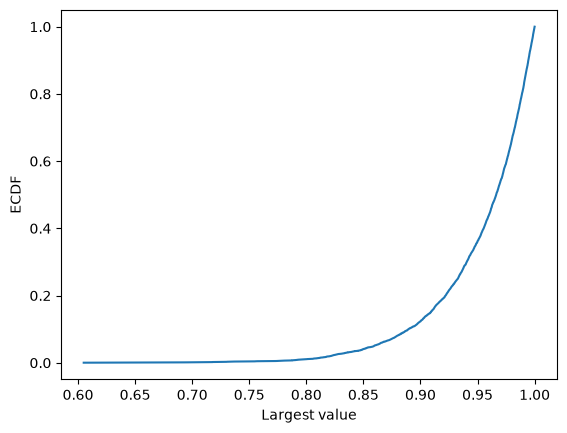

In [ ]:
from statsmodels.distributions.empirical_distribution import ECDF
import matplotlib.pyplot as plt

ecdf = ECDF(largest_values) #only doing the largest rank

plt.plot(ecdf.x, ecdf.y)
plt.xlabel("Largest value")
plt.ylabel("ECDF")
plt.show()

This is a beta distribution. Its showing the largest value out of 20 uniform draws. 

In [1]:
all_ranks = []

for rank in range(K):
    rank_values = []

    for i in range(n):
        data = np.random.uniform(0, 1, K)
        data = np.sort(data)
        rank_values.append(data[rank])

    all_ranks.append(rank_values)

NameError: name 'K' is not defined

In [19]:
all_ranks[0][:5]

[np.float64(0.017970204417816937),
 np.float64(0.015181911560494643),
 np.float64(0.010062701640047078),
 np.float64(0.042936734715827485),
 np.float64(0.002938380532936491)]

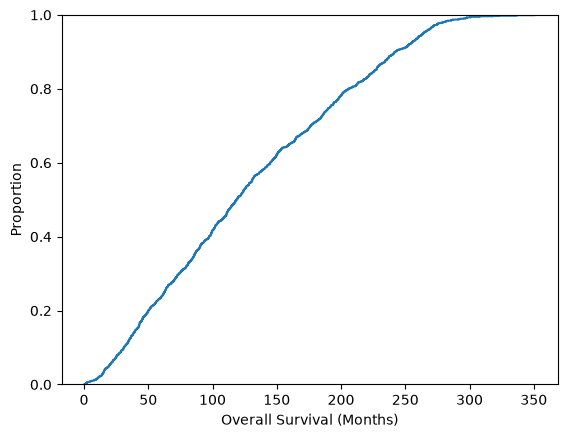

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

metabric = pd.read_csv("../data/metabric.csv")

sns.ecdfplot(data=metabric, x="Overall Survival (Months)")
plt.show()

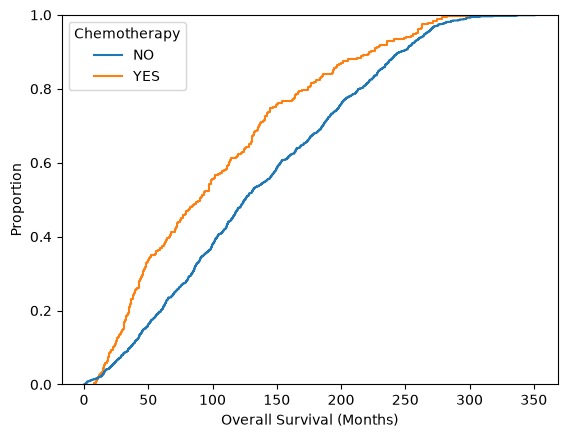

In [3]:
sns.ecdfplot(data=metabric, x="Overall Survival (Months)", hue="Chemotherapy")
plt.show()